# Analyses

Isaac T. Petersen, Zachary Demko, and Megan Schumer  
November 24, 2026

In [ ]:
#install.packages("remotes")
#remotes::install_github("DevPsyLab/petersenlab")


# Intro

# Preamble

## Install Libraries

## Load Libraries

In [ ]:

library("petersenlab") #located here: https://github.com/DevPsyLab/petersenlab
library("knitr")
library("magick")


Linking to ImageMagick 7.1.2.18
Enabled features: fontconfig, freetype, fftw, heic, lcms, raw, webp, x11
Disabled features: cairo, ghostscript, pango, rsvg

Using 3 threads

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.4     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     

── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

## Load Data

In [ ]:
longitudinalStudies <- read_csv("../Data/longitudinalStudies.csv") #read_csv("./Data/longitudinalStudies.csv")


Rows: 46 Columns: 17
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (6): study, studyLabel, designType, sampleType, country, continent
dbl (8): sampleSize, yearStart, yearMostRecentAssessment, yearEnd, ageStartM...
lgl (3): prenatalRecruitment, active, interventionPrevention

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

Rows: 20 Columns: 22
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (14): sample, sampleLabel, study, year, studyLabel, measurementOccasions...
dbl  (6): sampleSize, ageStartMin, ageStartMax, ageEndMin, ageEndMax, maxTim...
lgl  (2): registry, developmentalScaling

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

Rows: 30 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): facet, facetLabel, facetDefinition, positiveOpposite

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

# Plots

## Cognitive Trajectories

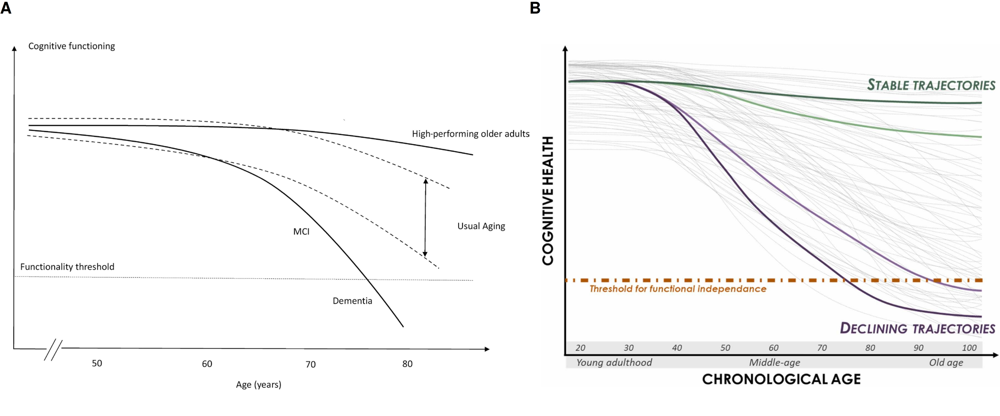

In [ ]:
#| apa-note:
#|   - "**Panel A**: Hypothetical models for different cognitive trajectories of aging. MCI = mild cognitive impairment. (Figure in Panel A reprinted from @Borelli2018, Figure 1, p. 222. Borelli, W. V., Carmona, K. C., Studart-Neto, A., Nitrini, R., Caramelli, P., & Costa, J. C. d. (2018). Operationalized definition of older adults with high cognitive performance. *Dementia & Neuropsychologia*, *12*(3), 221–227. <https://doi.org/10.1590/1980-57642018dn12-030001>)."
#|   - "**Panel B**: Theoretical illustration of inter-individual variability in cognitive aging trajectories. Each gray line represents one individual hypothetical cognitive health trajectory. The orange line marks the threshold for functional independence; once an individual's cognitive health drops below this level, autonomous daily living is compromised. (Figure in Panel B reprinted from @Abrous2026, Figure 1, p. 2. Abrous, D. N., Blin, N., Boraxbekk, C.-J., Catheline, G., Fitzsimons, C. P., Hilscher, M., Lemoine, M., Lopes, L. V., Maass, A., Nilsson, M., Nyberg, L., Rasmussen, L. J., Remondes, M., Sauvage, M., Schreiber, S., & Wolbers, T. (2026). Hallmarks of healthy cognitive aging: Inter-individual differences in aging trajectories. *Ageing Research Reviews*, *119*, 103102. <https://doi.org/10.1016/j.arr.2026.103102>)."

# Read images
lifespanCognitiveTrajectoriesFigA <- magick::image_read("../Figures/Borelli2018_figure1.jpg") #magick::image_read("./Figures/Borelli2018_figure1.jpg")
lifespanCognitiveTrajectoriesFigB <- magick::image_read("../Figures/Abrous2026_figure1.jpg") #magick::image_read("./Figures/Abrous2026_figure1.jpg")

# Convert images to patchwork-compatible objects
lifespanCognitiveTrajectoriesPanelA <- patchwork::wrap_elements(
  panel = grid::rasterGrob(as.raster(lifespanCognitiveTrajectoriesFigA), interpolate = TRUE)
) +
  labs(tag = "A")

lifespanCognitiveTrajectoriesPanelB <- patchwork::wrap_elements(
  panel = grid::rasterGrob(as.raster(lifespanCognitiveTrajectoriesFigB), interpolate = TRUE)
) +
  labs(tag = "B")

# Combine panels
lifespanCognitiveTrajectoriesPanelA + lifespanCognitiveTrajectoriesPanelB +
  patchwork::plot_layout(widths = c(53, 47)) &
  theme(
    plot.tag = element_text(face = "bold", size = 14),
    plot.margin = margin(0, 0, 0, 0)
  )


## Externalizing Trajectories

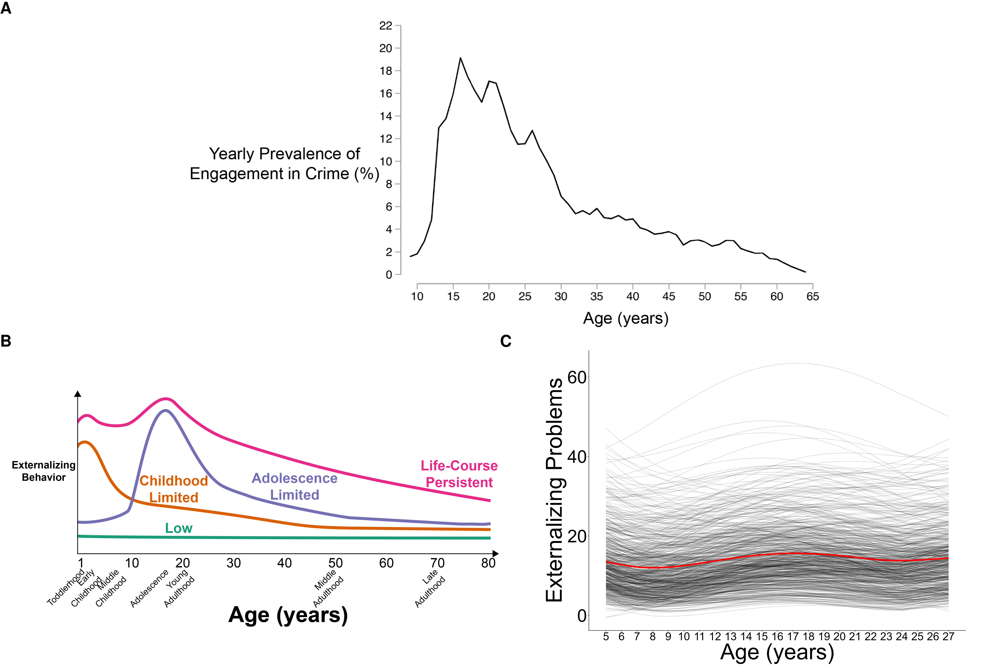

In [ ]:
#| apa-note:
#|   - "**Panel A**: The age-crime participation curve from age 9 through 64 in cohort members registered for antisocial and/or criminal behavior in a birth cohort recruited in Stockholm, Sweden (*N* = 4,825), based on official crime records. The steep peak in crime rate in the adolescent years is similar to the age-crime curve in the United States; however, the steepness of the age-crime curve differs within country across birth cohorts [@Steffensmeier2025]. (Figure adapted from @Sivertsson2024, Figure 1, p. 7. Sivertsson, F., Carlsson, C., Almquist, Y. B., & Brännström, L. (2024). Offending trajectories from childhood to retirement age: Findings from the Stockholm birth cohort study. *Journal of Criminal Justice*, *91*, 102155. <https://doi.org/10.1016/j.jcrimjus.2024.102155>)."
#|   - "**Panel B**: A stylized depiction of Moffitt's [-@Moffitt1993] developmental taxonomy of externalizing behavior, adapted to include a childhood limited subgroup."
#|   - "**Panel C**: Individuals' (*N* = 585) longitudinal trajectories of externalizing problems from childhood to adulthood based on annual assessments of mother-, father-, teacher-, peer-, and self-report (at relevant ages). Average trajectory in red. (Figure adapted from @Petersen2015, Figure 2, Petersen, I. T., Bates, J. E., Dodge, K. A., Lansford, J. E., & Pettit, G. S. (2015). Describing and predicting developmental profiles of externalizing problems from childhood to adulthood. *Development and Psychopathology*, *27*(3), 791–818. <https://doi.org/10.1017/S0954579414000789>)."

# Read images
externalizingByAgeFigA <- magick::image_read("../Figures/Sivertsson2024_figure1.png") #magick::image_read("./Figures/Sivertsson2024_figure1.png")
externalizingByAgeFigB <- magick::image_read("../Figures/developmentalTaxonomy.png") #magick::image_read("./Figures/developmentalTaxonomy.png")
externalizingByAgeFigC <- magick::image_read("../Figures/Petersen2015_adapted.png") #magick::image_read("./Figures/Petersen2015_adapted.png")

# Convert images to patchwork-compatible objects
externalizingByAgePanelA <- patchwork::wrap_elements(
  panel = grid::rasterGrob(as.raster(externalizingByAgeFigA), interpolate = TRUE)
) +
  labs(tag = "A")

externalizingByAgePanelB <- patchwork::wrap_elements(
  panel = grid::rasterGrob(as.raster(externalizingByAgeFigB), interpolate = TRUE)
) +
  labs(tag = "B")

externalizingByAgePanelC <- patchwork::wrap_elements(
  panel = grid::rasterGrob(as.raster(externalizingByAgeFigC), interpolate = TRUE)
) +
  labs(tag = "C")

# Combine panels
externalizingByAgePanelA /
(externalizingByAgePanelB + externalizingByAgePanelC) +
  patchwork::plot_layout(
    heights = c(1, 1)
  ) &
  theme(
    plot.tag = element_text(face = "bold", size = 14),
    plot.margin = margin(0, 0, 0, 0)
  )


## Longitudinal Studies

In [ ]:
# prepare data for plot
longitudinalStudies_plotData <- bind_rows(

  # ---- start cross-section ----
  longitudinalStudies %>%
    mutate(
      segment_group = "cross-section",
      segment_type = "start_crossSection",
      ageStart = ageStartMin,
      ageEnd = ageStartMax
    ) %>%
    select(study, studyLabel, ageStart, ageEnd, segment_group, segment_type),

  # ---- core (ONLY if true longitudinal cohort span exists) ----
  longitudinalStudies %>%
    mutate(has_cor = ageStartMax < ageEndMin) %>%
    filter(has_cor) %>%
    mutate(
      segment_group = "core",
      segment_type = "core",
      ageStart = ageStartMax,
      ageEnd = ageEndMin
    ) %>%
    select(study, studyLabel, ageStart, ageEnd, segment_group, segment_type),

  # ---- end cross-section ----
  longitudinalStudies %>%
    mutate(
      segment_group = "cross-section",
      segment_type = "end_crossSection",
      ageStart = ageEndMin,
      ageEnd = ageEndMax
    ) %>%
    select(study, studyLabel, ageStart, ageEnd, segment_group, segment_type)
)

# Merge active status
longitudinalStudies_plotData <- longitudinalStudies_plotData %>%
  left_join(
    longitudinalStudies %>% select(study, active),
    by = c("study")
  )

# Order studies for plot
study_order <- longitudinalStudies %>%
  arrange(ageEndMax, ageStartMin) %>%
  pull(studyLabel)

longitudinalStudies_plotData <- longitudinalStudies_plotData %>%
  mutate(studyLabelFactor = factor(studyLabel, levels = study_order))

# Prenatal enrollment
prenatal_df <- longitudinalStudies %>%
  filter(prenatalRecruitment == TRUE) %>%
  mutate(
    age = 0,
    studyLabelFactor = factor(studyLabel, levels = study_order)
  )


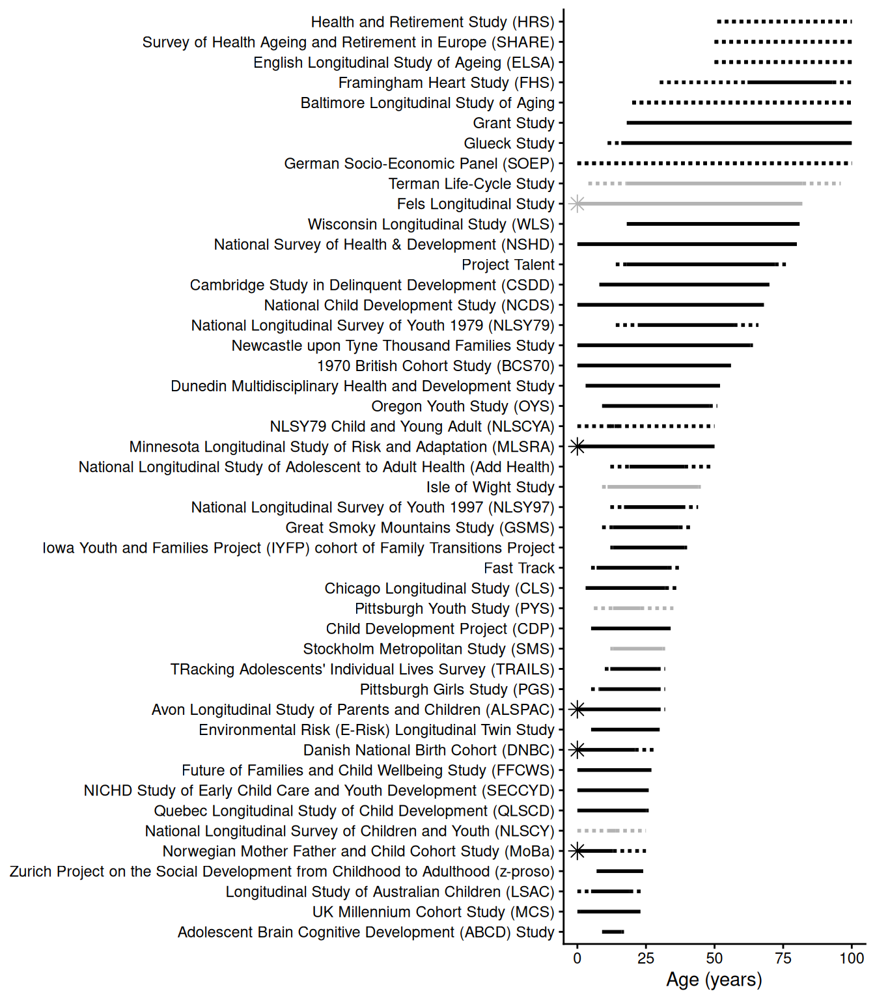

In [ ]:

plot_longitudinalStudies <- ggplot2::ggplot(
  data = longitudinalStudies_plotData,
  mapping = aes(
    y = studyLabelFactor
  )
) +
  geom_segment(
    aes(
      x = ageStart,
      xend = ageEnd,
      yend = studyLabelFactor,
      linetype = segment_group,
      color = active
    ),
    linewidth = 1
  ) +
  scale_linetype_manual(
    values = c(
      "cross-section" = "11",
      "core" = "solid"
    ),
    guide = "none"
  ) +
  scale_color_manual(
    values = c(
      "TRUE" = "black",
      "FALSE" = "gray70"
    ),
    guide = "none"
  ) +
  geom_point(
    data = prenatal_df,
    aes(
      x = age,
      y = studyLabelFactor,
      color = active
    ),
    shape = 8,
    size = 3
  ) +
  labs(
    x = "Age (years)",
    y = NULL
  ) +
  theme_classic()

plot_longitudinalStudies


## Longitudinal Externalizing Studies

In [ ]:
# Prepare plot data
longitudinalExternalizingStudies_plotData <- bind_rows(

  # start cross-sectional span
  longitudinalExternalizingStudies %>%
    mutate(
      segment_group = "cross-section",
      ageStart = ageStartMin,
      ageEnd = ageStartMax
    ) %>%
    select(
      sample,
      sampleLabel,
      study,
      studyLabel,
      ageStart,
      ageEnd,
      segment_group
    ),

  # core longitudinal span
  longitudinalExternalizingStudies %>%
    mutate(has_core = ageStartMax < ageEndMin) %>%
    filter(has_core) %>%
    mutate(
      segment_group = "core",
      ageStart = ageStartMax,
      ageEnd = ageEndMin
    ) %>%
    select(
      sample,
      sampleLabel,
      study,
      studyLabel,
      ageStart,
      ageEnd,
      segment_group
    ),

  # end cross-sectional span
  longitudinalExternalizingStudies %>%
    mutate(
      segment_group = "cross-section",
      ageStart = ageEndMin,
      ageEnd = ageEndMax
    ) %>%
    select(
      sample,
      sampleLabel,
      study,
      studyLabel,
      ageStart,
      ageEnd,
      segment_group
    )
)

# Merge registry/developmental scaling info
longitudinalExternalizingStudies_plotData <- longitudinalExternalizingStudies_plotData %>%
  left_join(
    longitudinalExternalizingStudies %>%
      select(study, registry, developmentalScaling),
    by = "study"
  ) %>%
  mutate(
    plotColor = case_when(
      developmentalScaling ~ "developmentalScaling",
      registry ~ "registry",
      TRUE ~ "standard"
    )
  )

# Study ordering
longitudinalExternalizingStudies_order <- longitudinalExternalizingStudies %>%
  arrange(ageEndMax, ageStartMin) %>%
  pull(studyLabel)

# Add numeric study positions
study_positions <- tibble(
  studyLabel = longitudinalExternalizingStudies_order,
  study_num = seq_along(longitudinalExternalizingStudies_order)
)

# Main plotting data
longitudinalExternalizingStudies_plotData <- longitudinalExternalizingStudies_plotData %>%
  left_join(study_positions, by = "studyLabel") %>%
  mutate(
    line_y = study_num + 0.25
  )

# Measurement occasions

longitudinalExternalizingStudies_measurementOccasions <- longitudinalExternalizingStudies %>%
  filter(!is.na(measurementOccasions)) %>%
  separate_rows(
    measurementOccasions,
    sep = ";"
  ) %>%
  mutate(
    measurementOccasions = as.numeric(str_trim(measurementOccasions))
  ) %>%
  left_join(study_positions, by = "studyLabel") %>%
  mutate(
    point_y = study_num + 0.45,
    plotColor = case_when(
      developmentalScaling ~ "developmentalScaling",
      registry ~ "registry",
      TRUE ~ "standard"
    )
  )

# Sample labels
longitudinalExternalizingStudies_sampleLabels <- longitudinalExternalizingStudies %>%
  left_join(study_positions, by = "studyLabel") %>%
  mutate(
    label_x = ageStartMin,
    label_y = study_num,
    plotColor = case_when(
      developmentalScaling ~ "developmentalScaling",
      registry ~ "registry",
      TRUE ~ "standard"
    )
  )


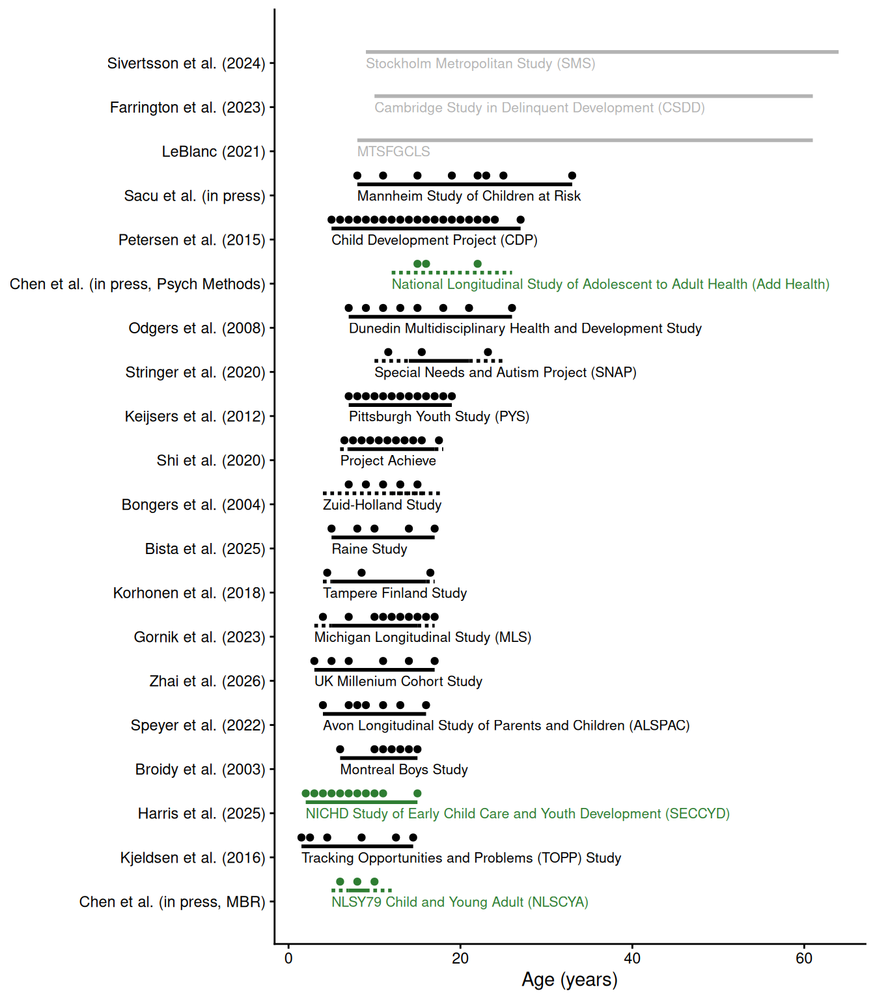

In [ ]:

plot_longitudinalExternalizingStudies <- ggplot2::ggplot() +
  geom_segment(
    data = longitudinalExternalizingStudies_plotData,
    aes(
      x = ageStart,
      xend = ageEnd,
      y = line_y,
      yend = line_y,
      linetype = segment_group,
      color = plotColor
    ),
    linewidth = 1
  ) +
  geom_point(
    data = longitudinalExternalizingStudies_measurementOccasions,
    aes(
      x = measurementOccasions,
      y = point_y,
      color = plotColor
    ),
    size = 1.5
  ) +
  geom_text(
    data = longitudinalExternalizingStudies_sampleLabels,
    aes(
      x = label_x,
      y = label_y,
      label = sampleLabel,
      color = plotColor
    ),
    hjust = 0,
    vjust = 0.5,
    size = 2.8
  ) +
  scale_y_continuous(
    breaks = study_positions$study_num,
    labels = study_positions$studyLabel
  ) +
  scale_linetype_manual(
    values = c(
      "cross-section" = "11",
      "core" = "solid"
    ),
    guide = "none"
  ) +
  scale_color_manual(
    values = c(
      standard = "black",
      registry = "gray70",
      developmentalScaling = "#2E7D32"
    ),
    guide = "none"
  ) +
  coord_cartesian(
    clip = "off"
  ) +
  labs(
    x = "Age (years)",
    y = NULL
  ) +
  theme_classic()

plot_longitudinalExternalizingStudies


# Tables

## Externalizing Facets

In [ ]:

knitr::kable(
  externalizingFacets %>% select(facetLabel, facetDefinition, positiveOpposite),
  col.names = c("Facet","Definition","Potential Positive Opposite")
)


  ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  Facet                                                                   Definition                                   Potential Positive Opposite
  ----------------------------------------------------------------------- -------------------------------------------- -------------------------------------------------------------------------
  Apathy/Indolence/Disengagement                                          Unconcerned about achievement, low           Diligence/Achievement motivation
                                                                          motivation, low concern about how one's      
                                                                          abilities or actions are evaluated, specific 
                                                                          to contexts in which others have             
                                                                          expectations for performance (e.g., school   
                                                                          and work), specifically low effort rather    
                                                                          than performance                             

  Attention seeking/Exhibitionism                                         Exaggerated or dramatic expressions,         Humility/Appropriate self-expression
                                                                          interrupting others, inappropriate or        
                                                                          provocative behaviors, provoking reactions   

  Behavioral addiction                                                    Impulsive/compulsive engagement in rewarding Self-regulated engagement
                                                                          non-substance behaviors (e.g., gambling,     
                                                                          video games, risky sex, pornography, food,   
                                                                          the internet, mobile devices, shopping)      

  Blame externalization                                                   Attribute cause of problems or failures to   Personal responsibility/Accountability
                                                                          external factors, falsely claiming           
                                                                          victimhood, blaming others                   

  Boredom proneness                                                       Expressing boredom often, difficulty         Curiosity/Sustained engagement
                                                                          maintaining interest, lack of engagement     

  Callous aggression                                                      Inflicting harm without feeling remorse or   Compassionate protection/Benevolence
                                                                          concern, usually proactive/intentional       

  Callousness/Disregard for others/Selfishness/Egocentricity              Emotional detachment, indifference to        Empathy/Compassion/Concern for others/Helping others/Sharing
                                                                          well-being of others                         

  Deceitfulness/Fraud/Lying/Cheating/Dishonesty/Sneakiness/Exploitation   Keeping the truth hidden, especially to get  Honesty/Integrity/Fairness
                                                                          an advantage (e.g., lying, withholding       
                                                                          information, manipulation, making false      
                                                                          promises)                                    

  Deviant peer affiliation                                                Affiliating with peers who engage in deviant Prosocial peer affiliations
                                                                          or delinquent behaviors                      

  Destructive aggression/Destruction of property                          Destruction of property, self, or others,    Constructiveness/Care for property
                                                                          objects                                      

  Distractibility/Inattention/Attention                                   Difficulty maintaining focus, attention, or  Attentional control/Sustained attention
  dysregulation/Forgetfulness/Daydreaming                                 concentration, frequent attention shifts     

  Domineering/Bossiness                                                   Asserting control, power, and authority in   Collaborativeness
                                                                          an overbearing or oppressive manner          

  Excitement seeking/Risk taking/Sensation seeking                        Tendency to impulsively pursue new and       Prudent exploration/Measured novelty seeking
                                                                          different sensations, especially ones that   
                                                                          are intense, exhilarating, thrilling,        
                                                                          unsafe, etc. (e.g., risk taking, preference  
                                                                          for novelty, intensity)                      

  Grandiosity/Overconfidence                                              Exaggerated sense of self-importance, sense  Realistic self-confidence
                                                                          of superiority or specialness                

  Hostility/Rudeness                                                      Hostile behavior, unfriendliness,            Warmth/Friendliness/Kindness
                                                                          resentment, antagonism, ranging from mild    
                                                                          irritation to intense rage, interpretation   
                                                                          of others' behavior as hostile               

  Hyperactivity                                                           High levels of physical activity,            Behavioral regulation
                                                                          restlessness, difficulty engaging in quiet   
                                                                          activities                                   

  Impulsivity/Disinhibition/Impatient urgency                             Tendency to act without thinking,            Planful control
                                                                          disinhibited engagement                      

  Irresponsibility/Unreliability/Disorganization                          Failing to meet obligations, avoiding        Responsibility/Conscientiousness/Dependability/Reliability/Organization
                                                                          addressing difficulties, inconsistency, lack 
                                                                          of organization and planning                 

  Manipulativeness/Psychological aggression                               Tendency to influence or control others to   Sincerity/Authenticity
                                                                          achieve one's own goals or desires (e.g.,    
                                                                          playing the victim, flattery, gaslighting,   
                                                                          guilt-tripping, psychological aggression)    

  Mistrust/Suspiciousness/Paranoia                                        Lack of confidence in the reliability and/or Interpersonal trust (appropriately calibrated)
                                                                          intentions of others, difficulty forming     
                                                                          close relationships with others, difficulty  
                                                                          forgiving                                    

  Oppositionality/Stubbornness                                            Persistent and defiant attitude, tendency to Cooperativeness
                                                                          challenge authority, refusal to comply,      
                                                                          argumentativeness (could include while       
                                                                          complying), etc.                             

  Physical aggression                                                     Use of physical force or violence to harm    Respect for others' bodies/Helping others
                                                                          others or their property                     

  Punishment insensitivity                                                Does not change behavior after punishment,   Responsive to consequences
                                                                          high tolerance for negative outcomes         

  Rebelliousness/Rule-breaking/Noncompliance                              Doing things differently than one is asked   Compliance/Civic responsibility
                                                                          to do (e.g., breaking house rules)           

  Relational aggression                                                   Aggression intended to harm others through   Inclusion
                                                                          deliberate manipulation of their social      
                                                                          standing and relationships (e.g., exclusion, 
                                                                          speaking negatively of another, etc.)        

  Sexual aggression                                                       Engaging in sexual activity with someone who Respect for consent
                                                                          does not or cannot consent to that behavior, 
                                                                          or threatening to do so (e.g., harassment)   

  Impulsive sexual behavior/Risky sexual behavior                         Engaging in risky sexual activity (e.g., sex Responsible sexual decision-making
                                                                          without contraceptives)                      

  (Harmful) Substance Use/Problems                                        Harmful use of any drugs (e.g., alcohol,     Healthy choices around substance use
                                                                          tobacco, illegal drugs)                      

  Theft/Stealing                                                          Unauthorized taking of someone else's        Respect for people's possessions
                                                                          property without their knowledge or consent  

  Verbal Aggression                                                       Communication with an intention to harm an   Respectful communication
                                                                          individual through words, tone, or manner    
  ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


# Session Info

In [ ]:
sessionInfo()


R version 4.6.2 (2026-10-29)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 26.04.1 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.32.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: UTC
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] lubridate_1.9.5   forcats_1.0.1     stringr_1.6.0     dplyr_1.2.1      
 [5] purrr_1.2.2       readr_2.2.0       tidyr_1.3.2       tibble_3.3.1     
 [9] ggplot2_4.0.4     tidyverse_2.0.0   patchwork_1.3.2   magick_2.9.1  

## Rstudio Version

In [ ]:
#rstudioapi::versionInfo()


Abrous, D. N., Blin, N., Boraxbekk, C.-J., Catheline, G., Fitzsimons, C. P., Hilscher, M., Lemoine, M., Lopes, L. V., Maass, A., Nilsson, M., Nyberg, L., Rasmussen, L. J., Remondes, M., Sauvage, M., Schreiber, S., & Wolbers, T. (2026). Hallmarks of healthy cognitive aging: <span class="nocase">Inter-individual</span> differences in aging trajectories. *Ageing Research Reviews*, *119*, 103102. <https://doi.org/10.1016/j.arr.2026.103102>

Borelli, W. V., Carmona, K. C., Studart-Neto, A., Nitrini, R., Caramelli, P., & Costa, J. C. da. (2018). Operationalized definition of older adults with high cognitive performance. *Dementia & Neuropsychologia*, *12*(3), 221–227. <https://doi.org/10.1590/1980-57642018dn12-030001>

Krueger, R. F., Hobbs, K. A., Conway, C. C., Dick, D. M., Dretsch, M. N., Eaton, N. R., Forbes, M. K., Forbush, K. T., Keyes, K. M., Latzman, R. D., Michelini, G., Patrick, C. J., Sellbom, M., Slade, T., South, S. C., Sunderland, M., Tackett, J. L., Waldman, I., Waszczuk, M. A., … Workgroup, H. U. (2021). Validity and utility of hierarchical taxonomy of psychopathology (HiTOP): II. Externalizing superspectrum. *World Psychiatry*, *20*(2), 171–193. <https://doi.org/10.1002/wps.20844>

Moffitt, T. E. (1993). Adolescence-limited and life-course-persistent antisocial behavior: A developmental taxonomy. *Psychological Review*, *100*(4), 674–701. <https://doi.org/10.1037/0033-295X.100.4.674>

Petersen, I. T., Bates, J. E., Dodge, K. A., Lansford, J. E., & Pettit, G. S. (2015). Describing and predicting developmental profiles of externalizing problems from childhood to adulthood. *Development and Psychopathology*, *27*(3), 791–818. <https://doi.org/10.1017/S0954579414000789>

Sivertsson, F., Carlsson, C., Almquist, Y. B., & Brännström, L. (2024). Offending trajectories from childhood to retirement age: Findings from the Stockholm birth cohort study. *Journal of Criminal Justice*, *91*, 102155. <https://doi.org/10.1016/j.jcrimjus.2024.102155>

Steffensmeier, D., Slepicka, J., & Schwartz, J. (2025). International and historical variation in the age–crime curve. *Annual Review of Criminology*, *8*, 239–268. <https://doi.org/10.1146/annurev-criminol-111523-122451>